# Question B: setpoint simulation, rule-based system and KPIs

IS4001 Smart Building Analytics project.

**Inputs** (run these notebooks first): `qb_comfort_pmv` (PMV per 15-min period, inspection list),
`qb_energy_per_degree` (AC kW saved per °C, moisture rise per °C) and `qb_baseline_model`
(weather-normalised AC baseline).

**What this notebook does**

1. **Scenarios:** every zone with an AC meter run from 5 °C cooler to 5 °C warmer during office hours. For each
   15-min period, the new temperature is today's + Δ; the humidity ratio rises by the zone's measured
   moisture slope (the AC removes less water), giving the new RH; PMV is recomputed. AC saved =
   slope × Δ, never more than the AC actually used in that period. A cooler zone uses extra AC,
   up to the zone's highest metered power. Beyond ±3 °C these figures are extrapolations.
2. **Rule-based setpoint system** (per zone, per month), as in the proposal:
   - raise 1 °C at a time while more than 25 % of office time is still too cool (PMV < -0.5);
   - otherwise lower 1 °C at a time while more than 25 % is too warm (PMV > +0.5), rolling back if
     more than 10 % would become too cool;
   - roll the last step back if it would make more than 10 % of office time too warm (PMV > +0.5) or
     push the share above 65 % RH past max(10 %, today's share);
   - cap at +5 °C and -5 °C; zones on the inspection list are not changed until checked on site.
3. **Ranking** of zones by kWh saved, for the facility management team.
4. **KPIs** before and after the recommended changes (Success KPIs slide).

**Main assumption:** the zone air temperature follows the setpoint, so "+1 °C setpoint" = "+1 °C
measured zone temperature". The rule thresholds are in `qb_common.py`, shared with the dashboard.

**Outputs** (`data/qns2/setpoint/`): `scenarios.csv`, `recommendations_monthly.csv`,
`recommendations_by_zone.csv`, `kpis.csv`, `savings_ranking.png`.

## 1. Settings and inputs

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import qb_common as qc
from qb_common import (BASELINE_DIR, COMFORT_DIR, SETPOINT_DIR, FLOORS, PERIOD_HOURS,
                       load_table, simulate_setpoint, summarise_sim, recommend_raise)

warnings.simplefilter("ignore", category=FutureWarning)

SCENARIOS_C = [d for d in range(-5, 6) if d]    # -5 to +5 °C; beyond qc.RELIABLE_CHANGE_C is extrapolated
MIN_PERIODS_PER_MONTH = 160     # a zone-month needs about 5 office days of data for a recommendation

print(f"Rule: raise {qc.RAISE_STEP_C:g} °C while > {qc.RAISE_IF_TOO_COOL_SHARE:.0%} too cool, or lower while "
      f"> {qc.LOWER_IF_TOO_WARM_SHARE:.0%} too warm, cap +{qc.MAX_RAISE_C:g} / -{qc.MAX_LOWER_C:g} °C; "
      f"roll back if > {qc.TOO_WARM_TOLERANCE:.0%} overshoots the comfort band or RH > {qc.RH_LIMIT:g} % beyond max({qc.HUMID_TOLERANCE:.0%}, today)")

pmv = pd.read_csv(COMFORT_DIR / "pmv_15min.csv", parse_dates=["timestamp"], index_col="timestamp")
inspection = pd.read_csv(COMFORT_DIR / "inspection_list.csv")
slopes = pd.read_csv(SETPOINT_DIR / "kw_per_degC.csv")

inspect_keys = set(zip(inspection["floor"], inspection["zone"]))
slope_of = {(r.floor, r.zone): (r.saving_kw_per_c, r.moisture_g_per_kg_per_c) for r in slopes.itertuples()}
ac_cap = pmv.groupby(["floor", "zone"])["ac_kw"].max().fillna(0.0)    # the most a cooler setpoint can draw
print(f"{len(slope_of)} zones with an AC slope; {len(inspect_keys)} zones on the inspection list")

Rule: raise 1 °C while > 25% too cool, or lower while > 25% too warm, cap +5 / -5 °C; roll back if > 10% overshoots the comfort band or RH > 65 % beyond max(10%, today)


23 zones with an AC slope; 2 zones on the inspection list


## 2. Scenarios: +1 °C and +2 °C over the whole sensor period

In [2]:
rows = []
for (floor, zone), z in pmv.groupby(["floor", "zone"]):
    if (floor, zone) not in slope_of:
        continue
    kw_per_c, dw = slope_of[(floor, zone)]
    for delta in [0] + SCENARIOS_C:
        sim = simulate_setpoint(z["temp_c"], z["rh_pct"], z["ac_kw"], delta, kw_per_c, dw, ac_cap[(floor, zone)])
        rows.append({"floor": floor, "zone": zone, "raise_c": delta,
                     "inspect_first": (floor, zone) in inspect_keys, **summarise_sim(sim)})
scenarios = pd.DataFrame(rows)
scenarios.to_csv(SETPOINT_DIR / "scenarios.csv", index=False)

building = scenarios.groupby("raise_c").apply(lambda d: pd.Series({
    "pct_too_cool": np.average(d["pct_too_cool"], weights=d["periods"]),
    "pct_comfortable": np.average(d["pct_comfortable"], weights=d["periods"]),
    "pct_too_warm": np.average(d["pct_too_warm"], weights=d["periods"]),
    "pct_humid": np.average(d["pct_humid"], weights=d["periods"]),
    "saved_kwh": d["saved_kwh"].sum(),
    "pct_ac_saved": d["saved_kwh"].sum() / d["ac_kwh"].sum() * 100})).round(1)
building

,pct_too_cool,pct_comfortable,pct_too_warm,pct_humid,saved_kwh,pct_ac_saved
raise_c,,,,,,
-5,99.6,0.4,0.0,50.3,-181826.8,-25.3
-4,98.7,1.3,0.0,49.6,-150987.9,-21.0
-3,97.0,2.9,0.1,48.4,-117741.8,-16.4
-2,93.9,5.8,0.3,46.5,-80962.7,-11.3
-1,86.5,12.5,0.9,43.9,-41200.9,-5.7
0,76.9,20.7,2.4,40.2,0.0,0.0
1,63.9,31.0,5.1,36.0,39145.4,5.4
2,40.2,48.9,10.9,31.3,78049.8,10.8
3,20.9,58.4,20.7,26.2,116753.2,16.2


## 3. Rule-based setpoint recommendations (per zone, per month)
Monthly, because the right setpoint changes with the season (Bangkok's hot season is Mar - May).

In [3]:
rows = []
for (floor, zone, month), z in pmv.groupby(["floor", "zone", "month"]):
    if (floor, zone) not in slope_of or len(z) < MIN_PERIODS_PER_MONTH:
        continue
    kw_per_c, dw = slope_of[(floor, zone)]
    cap = ac_cap[(floor, zone)]
    if (floor, zone) in inspect_keys:
        delta, reason = 0.0, "inspect before adjusting"
    else:
        delta, reason = recommend_raise(z["temp_c"], z["rh_pct"], z["ac_kw"], kw_per_c, dw, cap)
    before = summarise_sim(simulate_setpoint(z["temp_c"], z["rh_pct"], z["ac_kw"], 0.0, kw_per_c, dw, cap))
    after = summarise_sim(simulate_setpoint(z["temp_c"], z["rh_pct"], z["ac_kw"], delta, kw_per_c, dw, cap))
    rows.append({"floor": floor, "zone": zone, "month": month, "periods": len(z),
                 "recommended_raise_c": delta, "reason": reason,
                 "temp_before_c": before["mean_temp_c"], "temp_after_c": after["mean_temp_c"],
                 "pct_too_cool_before": before["pct_too_cool"], "pct_too_cool_after": after["pct_too_cool"],
                 "pct_comfortable_before": before["pct_comfortable"], "pct_comfortable_after": after["pct_comfortable"],
                 "pct_too_warm_after": after["pct_too_warm"],
                 "pct_humid_before": before["pct_humid"], "pct_humid_after": after["pct_humid"],
                 "ac_kwh": before["ac_kwh"], "saved_kwh": after["saved_kwh"], "pct_ac_saved": after["pct_ac_saved"]})
monthly = pd.DataFrame(rows)
monthly.to_csv(SETPOINT_DIR / "recommendations_monthly.csv", index=False)
print(monthly["recommended_raise_c"].value_counts().sort_index().rename("zone-months").to_string())
print()
print(monthly["reason"].value_counts().to_string())

recommended_raise_c
-2.0     1
 0.0    78
 1.0    32
 2.0    65
 3.0    64
 4.0    25
 5.0    17

reason
comfortable enough                   182
next step too warm (rolled back)      61
next step too humid (rolled back)     20
inspect before adjusting              12
reached +5 °C cap                      7


## 4. Zone ranking for the facility management team
Annualised savings scale the saved kWh per office period up to a full year of office hours
(the sensor data covers about 13 months, with a gap from mid-Sep 2018 to Feb 2019).

In [4]:
cal = load_table(FLOORS[0], "15min")
office_periods_per_year = int(cal.loc["2019", "is_occupied"].sum())

def zone_row(d: pd.DataFrame) -> pd.Series:
    w = d["periods"]
    return pd.Series({
        "months": len(d),
        "typical_raise_c": d["recommended_raise_c"].median(),
        "raise_range_c": f"{d['recommended_raise_c'].min():g} to {d['recommended_raise_c'].max():g}",
        "pct_too_cool_before": np.average(d["pct_too_cool_before"], weights=w),
        "pct_too_cool_after": np.average(d["pct_too_cool_after"], weights=w),
        "pct_comfortable_before": np.average(d["pct_comfortable_before"], weights=w),
        "pct_comfortable_after": np.average(d["pct_comfortable_after"], weights=w),
        "pct_humid_after": np.average(d["pct_humid_after"], weights=w),
        "saved_kwh": d["saved_kwh"].sum(),
        "pct_ac_saved": d["saved_kwh"].sum() / d["ac_kwh"].sum() * 100,
        "annual_kwh_saved": d["saved_kwh"].sum() / w.sum() * office_periods_per_year,
        "action": ("inspect first" if (d["reason"] == "inspect before adjusting").all()
                   else "lower setpoint" if d["recommended_raise_c"].median() < 0 else "raise setpoint"),
    })

by_zone = (monthly.groupby(["floor", "zone"]).apply(zone_row).round(1).reset_index()
           .sort_values("annual_kwh_saved", ascending=False).reset_index(drop=True))
by_zone.insert(0, "rank", range(1, len(by_zone) + 1))
by_zone.to_csv(SETPOINT_DIR / "recommendations_by_zone.csv", index=False)
print(f"Office periods per year (2019 calendar): {office_periods_per_year:,} "
      f"({office_periods_per_year * PERIOD_HOURS:,.0f} office hours)")
print(f"Estimated AC saved, Floors 2-7: {by_zone['annual_kwh_saved'].sum():,.0f} kWh per year")
by_zone

Office periods per year (2019 calendar): 7,776 (1,944 office hours)
Estimated AC saved, Floors 2-7: 85,874 kWh per year


,rank,floor,zone,months,typical_raise_c,raise_range_c,pct_too_cool_before,pct_too_cool_after,pct_comfortable_before,pct_comfortable_after,pct_humid_after,saved_kwh,pct_ac_saved,annual_kwh_saved,action
0,1,7,z4,13,3.0,0 to 4,84.0,29.5,13.8,63.0,6.4,8890.5,17.9,8812.3,raise setpoint
1,2,3,z4,13,4.0,1 to 5,92.9,32.6,6.3,61.1,3.6,7789.9,23.5,7735.2,raise setpoint
2,3,2,z2,13,2.0,-2 to 3,73.4,15.1,16.9,75.5,73.7,7239.8,13.0,7121.7,raise setpoint
3,4,7,z1,13,4.0,1 to 5,86.7,37.6,11.3,54.6,14.4,6825.1,10.9,6779.8,raise setpoint
4,5,2,z4,10,5.0,0 to 5,96.1,37.4,2.5,57.9,94.8,5136.4,38.7,6349.9,raise setpoint
5,6,4,z1,13,2.0,0 to 4,73.0,18.5,25.0,75.2,3.9,6120.1,14.8,6067.8,raise setpoint
6,7,5,z2,11,2.0,0 to 4,68.5,18.0,29.7,76.1,3.6,4005.4,16.8,5237.3,raise setpoint
7,8,5,z4,13,3.0,0 to 4,77.4,8.6,21.4,87.4,40.4,5024.4,16.6,5214.9,raise setpoint
8,9,7,z2,13,1.0,0 to 3,70.7,23.2,26.8,70.0,54.0,4747.7,9.6,4649.1,raise setpoint
9,10,6,z4,11,2.0,0 to 2,85.1,30.7,13.9,65.3,11.4,3596.3,13.2,4325.6,raise setpoint


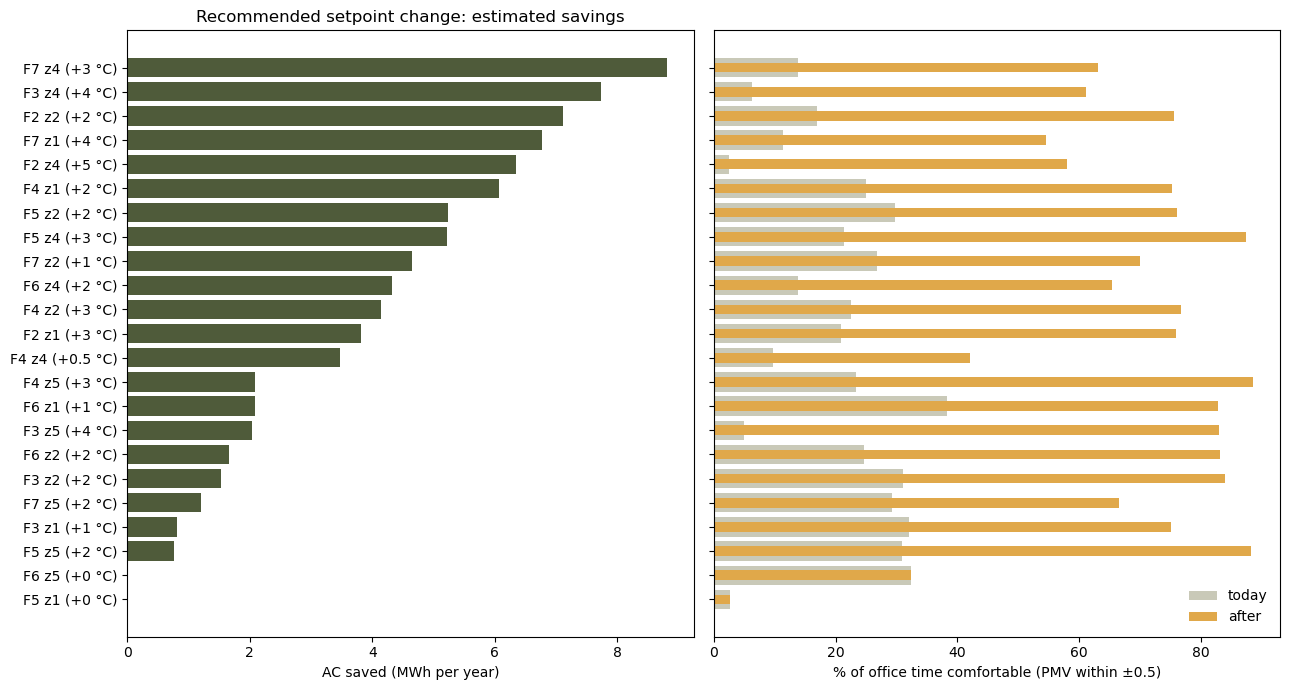

In [5]:
top = by_zone.sort_values("annual_kwh_saved")
labels = "F" + top["floor"].astype(str) + " " + top["zone"] + " (" + top["typical_raise_c"].map("{:+g}".format) + " °C)"
fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
axes[0].barh(labels, top["annual_kwh_saved"] / 1000, color="#4f5b3a")
axes[0].set_xlabel("AC saved (MWh per year)")
axes[0].set_title("Recommended setpoint change: estimated savings")
axes[1].barh(labels, top["pct_comfortable_before"], color="#c9c9b8", label="today")
axes[1].barh(labels, top["pct_comfortable_after"], color="#e0a84a", height=0.4, label="after")
axes[1].set_xlabel("% of office time comfortable (PMV within ±0.5)")
axes[1].legend(loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig(SETPOINT_DIR / "savings_ranking.png", dpi=130)
plt.show()

## 5. Success KPIs (before vs after the recommended changes)
- **AC energy per office hour:** today, from the actual meters and from the weather-normalised
  baseline (all office hours, Jul 2018 - Dec 2019, zones with a baseline); after = today ×
  (1 - share of AC saved in the simulation).
- **Too-cool / comfortable hours:** all zones with sensors; zones not changed keep today's values.
- **Peak cooling demand:** highest 15-min AC kW for Floors 2-7 together on office days, in the months
  with sensor data (the only months the simulation covers).

In [6]:
# AC energy per office hour, Floors 2-7 zones with a baseline
preds = pd.concat(pd.read_csv(BASELINE_DIR / f"floor{f}" / "predictions_occupied_hours.csv",
                              parse_dates=["timestamp"]).assign(floor=f) for f in FLOORS)
per_hour = preds.groupby("timestamp")[["ac_kw", "pred_chosen"]].sum()
share_saved = monthly["saved_kwh"].sum() / monthly["ac_kwh"].sum()

# Comfort, all sensor zones: apply each zone-month's recommended raise
after_frames = []
raise_of = monthly.set_index(["floor", "zone", "month"])["recommended_raise_c"]
for (floor, zone, month), z in pmv.groupby(["floor", "zone", "month"]):
    delta = raise_of.get((floor, zone, month), 0.0)
    kw_per_c, dw = slope_of.get((floor, zone), (0.0, 0.0))
    after_frames.append(simulate_setpoint(z["temp_c"], z["rh_pct"], z["ac_kw"], delta, kw_per_c, dw, ac_cap[(floor, zone)])
                        .assign(floor=floor, zone=zone))
after = pd.concat(after_frames)

# Peak cooling demand on office days, months with sensor data
ac_total = sum(load_table(f, "15min").loc[lambda d: d["is_occupied"], "floor_ac_kw"] for f in FLOORS).dropna()
ac_total = ac_total[ac_total.index.isin(pmv.index.unique())]
saved_at = after.groupby(level=0)["saved_kw"].sum().reindex(ac_total.index, fill_value=0)

kpis = pd.DataFrame([
    ("AC energy per office hour (actual)", "Energy", "AC kWh ÷ office hours, Floors 2-7",
     per_hour["ac_kw"].mean(), per_hour["ac_kw"].mean() * (1 - share_saved), "kWh/h"),
    ("AC energy per office hour (weather-normalised)", "Energy", "Baseline-model kWh ÷ office hours",
     per_hour["pred_chosen"].mean(), per_hour["pred_chosen"].mean() * (1 - share_saved), "kWh/h"),
    ("Too-cool hours", "Comfort", "% office time with PMV < -0.5",
     (pmv["comfort"] == "too cool").mean() * 100, (after["comfort"] == "too cool").mean() * 100, "%"),
    ("Comfortable hours", "Comfort", "% office time with PMV within ±0.5",
     (pmv["comfort"] == "comfortable").mean() * 100, (after["comfort"] == "comfortable").mean() * 100, "%"),
    ("Too-warm hours", "Comfort (guardrail)", "% office time with PMV > +0.5",
     (pmv["comfort"] == "too warm").mean() * 100, (after["comfort"] == "too warm").mean() * 100, "%"),
    ("Too-humid hours", "Comfort (guardrail)", "% office time with RH > 65 %",
     pmv["humid"].mean() * 100, after["humid"].mean() * 100, "%"),
    ("Peak cooling demand", "Energy", "Highest 15-min AC kW on office days, Floors 2-7",
     ac_total.max(), (ac_total - saved_at).max(), "kW"),
], columns=["kpi", "type", "definition", "today", "after", "unit"])
kpis["change_pct"] = ((kpis["after"] - kpis["today"]) / kpis["today"] * 100).round(1)
kpis[["today", "after"]] = kpis[["today", "after"]].round(1)
kpis.to_csv(SETPOINT_DIR / "kpis.csv", index=False)
print(f"Share of AC energy saved in the simulated periods: {share_saved:.1%}")
kpis

Share of AC energy saved in the simulated periods: 11.3%


,kpi,type,definition,today,after,unit,change_pct
0,AC energy per office hour (actual),Energy,"AC kWh ÷ office hours, Floors 2-7",365.7,324.4,kWh/h,-11.3
1,AC energy per office hour (weather-normalised),Energy,Baseline-model kWh ÷ office hours,363.3,322.3,kWh/h,-11.3
2,Too-cool hours,Comfort,% office time with PMV < -0.5,73.5,24.0,%,-67.3
3,Comfortable hours,Comfort,% office time with PMV within ±0.5,22.1,68.5,%,209.2
4,Too-warm hours,Comfort (guardrail),% office time with PMV > +0.5,4.4,7.5,%,71.4
5,Too-humid hours,Comfort (guardrail),% office time with RH > 65 %,38.5,25.9,%,-32.6
6,Peak cooling demand,Energy,"Highest 15-min AC kW on office days, Floors 2-7",663.4,629.0,kW,-5.2
